# The Synthesizer

`Synthesizer` sends a string through five stages.

1. Text rules (optional)
2. Font patches (optional)
3. Shaping and layout
4. Glyph rules (optional)
5. Effects (optional)

In [ ]:
from textsynth import (
    Blobify,
    BorrowedGlyph,
    GlyphSubstitution,
    InkBleed,
    Layout,
    Smudge,
    Speckle,
    Synthesizer,
    TadakhulMerged,
    orthographic_variation,
)
from nbutil import DONOR, FONT, sheet

TEXT = "سايا ممباچ سورت خبر"  # "saya membaca surat khabar" — "I read the newspaper"

### The default

With no rules and no effects, `Synthesizer` only shapes the text.

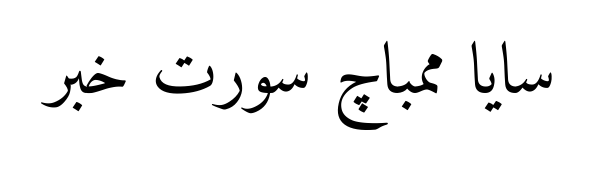

In [2]:
plain = Synthesizer(font=FONT, layout=Layout(size=72))
plain(TEXT)

### All five stages

This example uses each of the five stages.

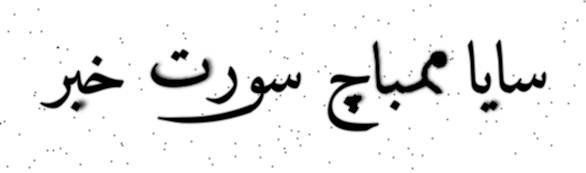

In [3]:
everything = Synthesizer(
    font=FONT,
    layout=Layout(size=72, tracking=-1, supersample=2, jitter_y=0.6),
    text_rules=[orthographic_variation(swap=0.35)],
    font_patches=[GlyphSubstitution("مم", BorrowedGlyph(DONOR, "A"))],
    glyph_rules=[TadakhulMerged(letters="و", length=2)],
    effects=[
        Smudge(length=6),
        Blobify(),
        InkBleed(1.0, strength=0.6),
        Speckle(density=0.0015),
    ],
    seed=7,
)
everything(TEXT)

### One stage at a time

Each row adds one stage to the row above it.

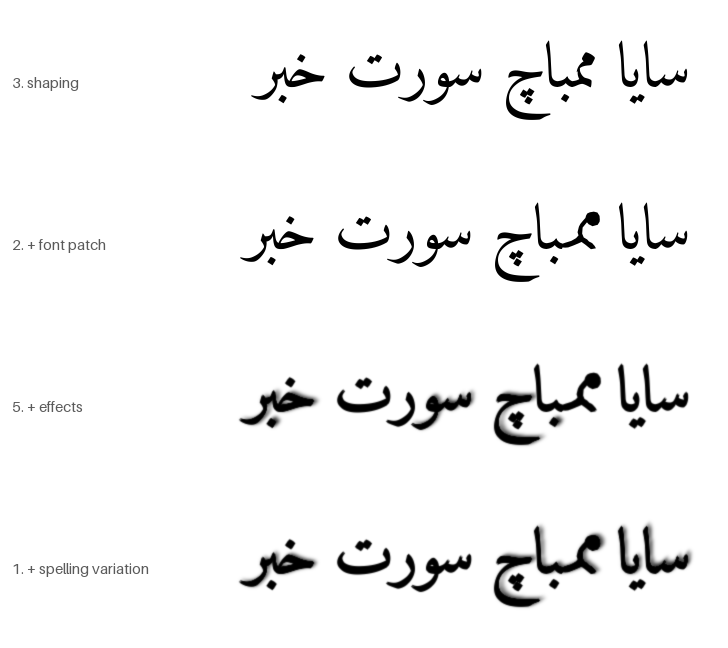

In [4]:
mim = GlyphSubstitution("مم", BorrowedGlyph(DONOR, "A"))
layout = Layout(size=64, tracking=-1, supersample=2)

rows = [
    ("3. shaping", Synthesizer(font=FONT, layout=layout)(TEXT)),
    (
        "2. + font patch",
        Synthesizer(font=FONT, layout=layout, font_patches=[mim])(TEXT),
    ),
    (
        "5. + effects",
        Synthesizer(
            font=FONT,
            layout=layout,
            font_patches=[mim],
            effects=[Smudge(length=6), Blobify(), InkBleed(1.0)],
            seed=7,
        )(TEXT),
    ),
    (
        "1. + spelling variation",
        Synthesizer(
            font=FONT,
            layout=layout,
            font_patches=[mim],
            text_rules=[orthographic_variation(swap=0.4)],
            effects=[Smudge(length=6), Blobify(), InkBleed(1.0)],
            seed=3,
        )(TEXT),
    ),
]
sheet(rows, gutter=200)

### The seed

The same seed gives the same image.

In [5]:
import numpy as np

for seed in range(3):
    spelling = everything.apply_text_rules(TEXT, np.random.default_rng(seed))
    print(f"seed {seed}: {spelling}")

a = everything.render(TEXT, seed=1)
b = everything.render(TEXT, seed=1)
print("same seed, identical image:", np.array_equal(np.asarray(a), np.asarray(b)))

seed 0: سايا ممباچ سۏرت خبر
seed 1: سايا ممباچ سورت خبر
seed 2: سایا ممباچ سورت خبر
same seed, identical image: True
